# MAESTRO training-loss analysis

Compare the small, medium, and large models using the recorded evaluation checkpoints. This notebook reads local results; it does not launch training or need a GPU.

Run cells from top to bottom. Change `RUN_NAME` below to analyze another downloaded experiment. Figures display inline and export as PNG/PDF into **`plots/<RUN_NAME>/`**, separately from the input metrics in `results/`.

Dependencies: `numpy`, `pandas`, `matplotlib`, and a Jupyter Python kernel. If needed, install them in your selected environment using `%pip install numpy pandas matplotlib ipykernel` and restart the kernel.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

# Locate the repository from a kernel started in its root or a subdirectory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'modified-nanoGPT').is_dir() and (p / 'results').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Start this notebook from the project directory.')

RUN_NAME = 'maestro-20261104-optimized-v1'
RUN_DIR = ROOT / 'results' / RUN_NAME
PLOT_DIR = ROOT / 'plots' / RUN_NAME
PLOT_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {'small': '#0072B2', 'medium': '#D55E00', 'large': '#009E73'}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'pdf.fonttype': 42})
print('Read metrics from:', RUN_DIR)
print('Save figures to:', PLOT_DIR)

Matplotlib is building the font cache; this may take a moment.


Read metrics from: /Users/chloeheh/Documents/DSA4212/DSA4212-project/results/maestro-20261104-optimized-v1
Save figures to: /Users/chloeheh/Documents/DSA4212/DSA4212-project/plots/maestro-20261104-optimized-v1


## Load the recorded checkpoints

Each `metrics.csv` row is an evaluation on fixed train/validation windows, with dropout disabled. Loss is next-token cross-entropy in nats/token; lower is better. The first row is the untrained model. Subsequent points were recorded approximately every ten minutes. Lines only connect these measurements; they are not additional observations.

In [2]:
metrics = {}
frames = []
for size in COLORS:
    path = RUN_DIR / size / 'metrics.csv'
    frame = pd.read_csv(path)
    required = ['elapsed_seconds', 'step', 'tokens_seen', 'train_loss', 'val_loss']
    if frame.empty or not np.isfinite(frame[required].to_numpy(dtype=float)).all():
        raise ValueError(f'Empty or non-finite metrics: {path}')
    if not frame['elapsed_seconds'].is_monotonic_increasing:
        raise ValueError(f'Checkpoints are not ordered by time: {path}')
    frame['minutes'] = frame['elapsed_seconds'] / 60
    metrics[size] = {column: frame[column].to_numpy() for column in frame.columns}
    frames.append(frame.assign(model=size))

checkpoints = pd.concat(frames, ignore_index=True)
display(checkpoints[['model', 'step', 'minutes', 'train_loss', 'val_loss']].round(4))

,model,step,minutes,train_loss,val_loss
0,small,0,0.0077,5.9357,5.9365
1,small,10715,10.0122,1.8109,1.8967
2,small,21324,20.0187,1.7204,1.8320
3,small,31925,30.0252,1.6749,1.8101
4,small,42535,40.0330,1.6544,1.7980
5,small,53159,50.0409,1.6359,1.7884
6,small,63785,60.0479,1.6193,1.7844
7,small,74406,70.0557,1.6029,1.7753
8,small,85019,80.0644,1.5914,1.7694
9,small,95633,90.0737,1.5817,1.7681


## Summarize best checkpoints

The best checkpoint is selected using validation loss, not training loss. The generalization gap below is final validation loss minus final training loss. These are sampled evaluation losses, not averages over the entire splits.

In [3]:
rows = []
for size, data in metrics.items():
    best = int(np.argmin(data['val_loss']))
    rows.append({
        'model': size,
        'best_step': int(data['step'][best]),
        'best_minutes': data['minutes'][best],
        'tokens_at_best': int(data['tokens_seen'][best]),
        'best_val_loss': data['val_loss'][best],
        'best_val_perplexity': np.exp(data['val_loss'][best]),
        'final_train_loss': data['train_loss'][-1],
        'final_val_loss': data['val_loss'][-1],
        'final_generalization_gap': data['val_loss'][-1] - data['train_loss'][-1],
        'val_increase_from_best': data['val_loss'][-1] - data['val_loss'][best],
    })
summary = pd.DataFrame(rows)
summary.to_csv(PLOT_DIR / 'checkpoint_summary.csv', index=False)
display(summary.round(4))

,model,best_step,best_minutes,tokens_at_best,best_val_loss,best_val_perplexity,final_train_loss,final_val_loss,final_generalization_gap,val_increase_from_best
0,small,116873,110.0902,3829694464,1.7652,5.8429,1.5603,1.7659,0.2055,0.0006
1,medium,13610,40.0820,445972480,1.8018,6.0606,1.3299,1.8892,0.5593,0.0874
2,large,6466,50.2836,211877888,1.8122,6.1241,1.2865,1.9224,0.6360,0.1102


## Training and validation curves for each model

The top row includes initialization. The bottom row omits initialization and uses a shared zoomed y-axis to reveal later progress. Stars mark the best recorded validation checkpoints. PNG and PDF copies are saved when the plotting cell runs.

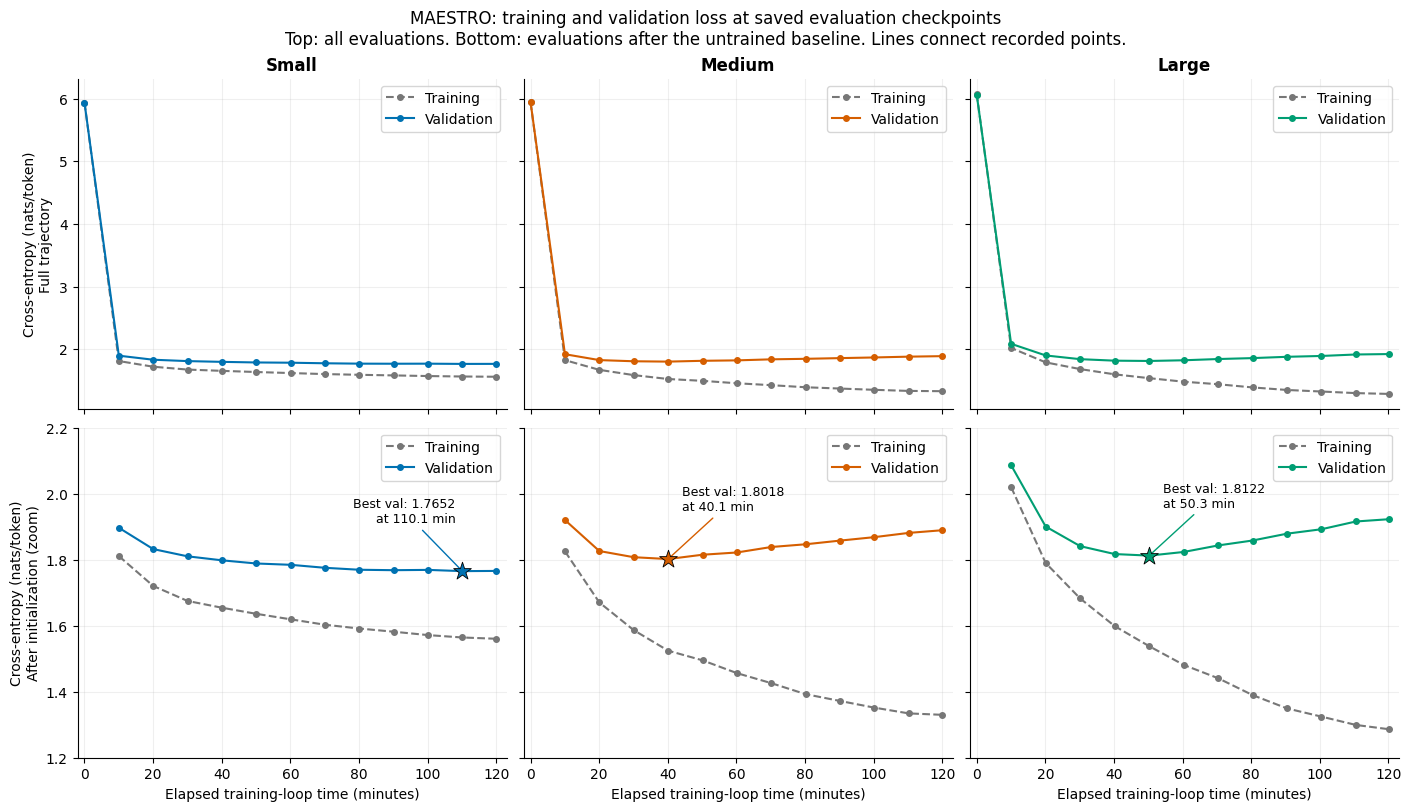

In [4]:
def save_figure(fig, name):
    for extension in ('png', 'pdf'):
        fig.savefig(PLOT_DIR / f'{name}.{extension}', dpi=200, bbox_inches='tight')

fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey='row', layout='constrained')
for column, (size, data) in enumerate(metrics.items()):
    for row in (0, 1):
        ax = axes[row, column]
        include = np.ones(len(data['step']), dtype=bool) if row == 0 else data['step'] > 0
        ax.plot(data['minutes'][include], data['train_loss'][include], 'o--',
                color='#777777', label='Training', markersize=4)
        ax.plot(data['minutes'][include], data['val_loss'][include], 'o-',
                color=COLORS[size], label='Validation', markersize=4)
        ax.grid(alpha=0.2)
        ax.set_xlim(-2, 123)
        ax.set_xticks(np.arange(0, 121, 20))
        ax.legend(loc='upper right')
    axes[0, column].set_title(size.capitalize(), fontweight='bold')
    axes[1, column].set_xlabel('Elapsed training-loop time (minutes)')
    best = int(np.argmin(data['val_loss']))
    ax = axes[1, column]
    ax.scatter(data['minutes'][best], data['val_loss'][best], marker='*', s=180,
               color=COLORS[size], edgecolors='black', linewidths=0.6, zorder=5)
    ax.annotate(f"Best val: {data['val_loss'][best]:.4f}\nat {data['minutes'][best]:.1f} min",
                xy=(data['minutes'][best], data['val_loss'][best]),
                xytext=(-5 if size == 'small' else 10, 35), textcoords='offset points',
                ha='right' if size == 'small' else 'left', fontsize=9,
                arrowprops={'arrowstyle': '-', 'color': COLORS[size]})
axes[0, 0].set_ylabel('Cross-entropy (nats/token)\nFull trajectory')
axes[1, 0].set_ylabel('Cross-entropy (nats/token)\nAfter initialization (zoom)')
axes[1, 0].set_ylim(1.2, 2.2)
fig.suptitle('MAESTRO: training and validation loss at saved evaluation checkpoints\n'
             'Top: all evaluations. Bottom: evaluations after the untrained baseline. '
             'Lines connect recorded points.', fontsize=12)
save_figure(fig, 'learning_curves')
plt.show()
plt.close(fig)

## Compare validation progress across sizes

The following figure overlays validation losses after initialization. All sizes use identical evaluation windows, but they process different numbers of training tokens within the two-hour budget.

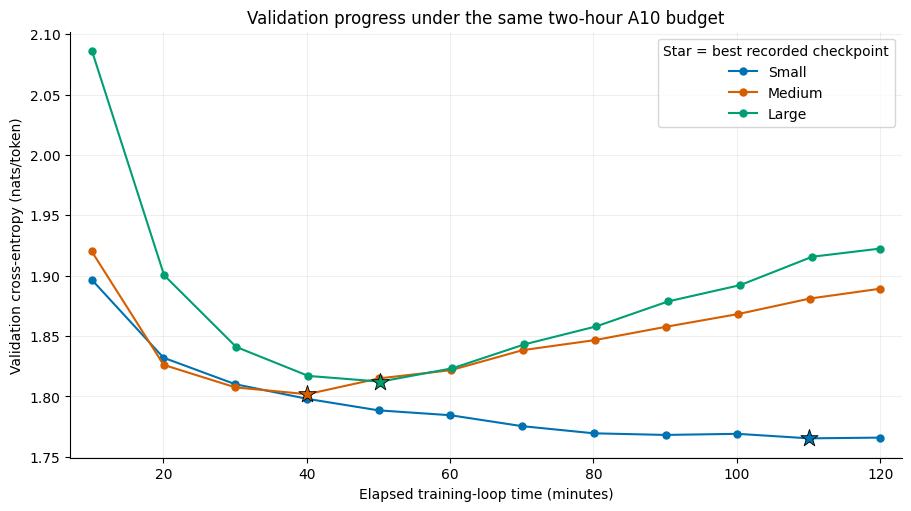

In [5]:
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
for size, data in metrics.items():
    keep = data['step'] > 0
    ax.plot(data['minutes'][keep], data['val_loss'][keep], 'o-', color=COLORS[size],
            label=size.capitalize(), markersize=5)
    best = int(np.argmin(data['val_loss']))
    ax.scatter(data['minutes'][best], data['val_loss'][best], marker='*', s=170,
               color=COLORS[size], edgecolors='black', linewidths=0.6, zorder=5)
ax.set(xlabel='Elapsed training-loop time (minutes)', ylabel='Validation cross-entropy (nats/token)',
       title='Validation progress under the same two-hour A10 budget', xlim=(7, 123))
ax.grid(alpha=0.2)
ax.legend(title='Star = best recorded checkpoint')
save_figure(fig, 'validation_comparison')
plt.show()
plt.close(fig)

## Interpretation of the current run

- **Small:** best recorded validation loss is about 1.7652 at 110.1 minutes; validation largely plateaus late in training.
- **Medium:** best recorded validation loss is about 1.8018 at 40.1 minutes. Validation then rises while training loss continues falling.
- **Large:** best recorded validation loss is about 1.8122 at 50.3 minutes, followed by the same widening training/validation separation.

The medium and large trajectories provide evidence of overfitting under these settings. Their best checkpoints should be evaluated rather than automatically choosing their final checkpoints. The small model has the lowest observed validation loss under this fixed-time budget; this is not proof that smaller models are generally superior. These are single-seed results on sampled validation windows, and token counts differ substantially.

This interpretation refers to `maestro-20261104-optimized-v1`; revisit it if you change the run. The best recorded time has roughly ten-minute resolution, not a precisely measured optimal stopping time.

In [6]:
display(pd.DataFrame({'exported_file': [str(p.relative_to(ROOT)) for p in sorted(PLOT_DIR.iterdir()) if p.is_file()]}))

,exported_file
0,plots/maestro-20261104-optimized-v1/checkpoint...
1,plots/maestro-20261104-optimized-v1/learning_c...
2,plots/maestro-20261104-optimized-v1/learning_c...
3,plots/maestro-20261104-optimized-v1/validation...
4,plots/maestro-20261104-optimized-v1/validation...
